# Binary Prediction

## Predicting Probabilities
- OLS/SSE is great, powerful, simple; not the end of the story, but it's hard to understate how useful it can be
- But it places no restrictions on the values it can predict
- Often we need real probabilities: Values between 0 and 1 that represent the likelihood something happens
- OLS can yield probabilities above 1 and below 0. 
- What's a good alternative?

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv('./data/heart_failure_clinical_records_dataset.csv')
print(df.head())

y = df['DEATH_EVENT']
X = df.drop(['DEATH_EVENT', 'time'],axis=1)

    age  anaemia  creatinine_phosphokinase  diabetes  ejection_fraction  \
0  75.0        0                       582         0                 20   
1  55.0        0                      7861         0                 38   
2  65.0        0                       146         0                 20   
3  50.0        1                       111         0                 20   
4  65.0        1                       160         1                 20   

   high_blood_pressure  platelets  serum_creatinine  serum_sodium  sex  \
0                    1  265000.00               1.9           130    1   
1                    0  263358.03               1.1           136    1   
2                    0  162000.00               1.3           129    1   
3                    0  210000.00               1.9           137    1   
4                    0  327000.00               2.7           116    0   

   smoking  time  DEATH_EVENT  
0        0     4            1  
1        0     6            1  
2       

In [2]:
import statsmodels.api as sm
X = sm.add_constant(X)

model = sm.OLS(y, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:            DEATH_EVENT   R-squared:                       0.236
Model:                            OLS   Adj. R-squared:                  0.207
Method:                 Least Squares   F-statistic:                     8.063
Date:                Thu, 12 Nov 2026   Prob (F-statistic):           2.92e-12
Time:                        01:23:18   Log-Likelihood:                -156.26
No. Observations:                 299   AIC:                             336.5
Df Residuals:                     287   BIC:                             380.9
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------
const                   

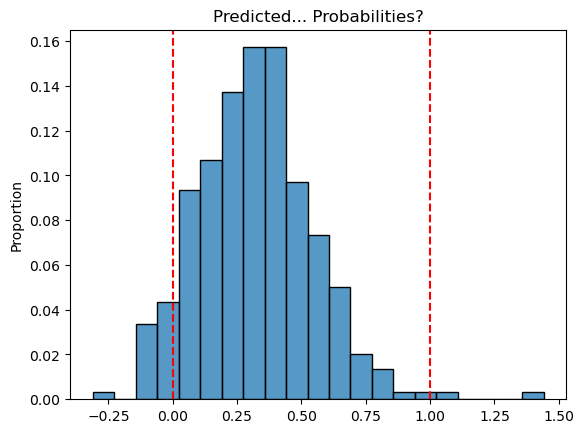

In [3]:
y_hat = model.predict(X)
sns.histplot(y_hat,stat='proportion').set(title='Predicted... Probabilities?')
plt.axvline(x=0, color='red', linestyle='--')
plt.axvline(x=1, color='red', linestyle='--')

# 1. Bernoulli 

## The MLE Approach

1. Derive the individual density/probability terms for each observation, as appropriate
2. Multiply the terms together to get the likelihood (the density of the data, given parameters). Take logs to get the log likelihood
3. Maximize over parameters

## Parametric Binary
- Imagine that we observe $y_i = 1$ with probability $p$, and $y_i = 0$ with probability $1-p$
- If there are $n$ observations of this process, we want to estimate $p$
- This random variable follows a Bernoulli Distribution, so we can write the likelihood down and maximize it

## (1) Individual Terms
- There is a clever and very common way to write the "switching" between $y_i=1$ and $y_i=0$ as part of the likelihood:
$$
p[Y=y] = p^{y} \times (1-p)^{1-y}
$$
- When $y_i=1$, this takes the value $p \times 1$, and then $y_i=0$, it takes the value $1 \times (1-p)$
- This trick gets used so very often, please make sure you understand it
- The expected value, of course, is
$$
\mathbb{E}[Y] = p \times 1 + (1-p) \times 0 = p
$$
Remember what $p$ is, for later!

## (2) Log-Likelihood 
- To form the likelihood, take the product of the probabilities of observing each value of $y_i$:
$$
\mathcal{L}[y|p] = \prod_{i=1}^n p^{y_i} (1-p)^{1-y_i}
$$
- And the log-likelihood is
$$
L(p) = \sum_{i=1}^n y_i \log\left(p\right)+ (1-y_i) \log \left(  1-p \right)
$$
- Computer scientists call $-L(p)$ the **binary cross entropy** or **log-loss**

## (3) Maximize
- Maximizing our loglikelihood yields:
$$
L'(\hat{p}) = \sum_{i=1}^n \frac{y_i}{\hat{p}} - \dfrac{1-y_i}{1-\hat{p}}=0
$$
- Let's simplify:
\begin{alignat*}{2}
\sum_{i=1}^n \frac{y_i}{\hat{p}} &=& \sum_{i=1}^n\dfrac{1-y_i}{1-\hat{p}} \\
 \frac{\sum_{i=1}^ny_i}{\hat{p}} &=& \dfrac{n-\sum_{i=1}^ny_i}{1-\hat{p}} \\
(1-\hat{p}) \sum_{i=1}^ny_i &=& n\hat{p}-\hat{p} \sum_{i=1}^n y_i\\
 \sum_{i=1}^ny_i &=& n\hat{p}\\
\frac{1}{n} \sum_{i=1}^ny_i &=& \hat{p}\\
\end{alignat*}
- So the MLE of $\hat{p}$ is the sample average of $y_i$

## Inference
- Since this is the sample mean, again, but with binary 0/1 values, we know that
$$
\text{SE}(\hat{p}) = \frac{\hat{p}(1-\hat{p})}{\sqrt{n}}
$$
- The 90% CI is then
$$
\left( \hat{p} - 1.645 \times \frac{\hat{p}(1-\hat{p})}{\sqrt{n}}, \quad \hat{p} + 1.645 \times \frac{\hat{p}(1-\hat{p})}{\sqrt{n}}\right) 
$$

## Prediction
- With binary outcomes, we don't get a prediction interval, since only two outcomes are possible:
$$
\begin{cases}
y = 1, & \hat{p} \\
y = 0, & 1 - \hat{p}
\end{cases}
$$

# 2. Parameterization

## Parameterizing the Log-Loss
- If you set $p_i = x_i \beta$, you can't guarantee that $0 \le p_i \le 1$
- But we want to leverage all of that sweet, sweet data
- We introduce a concept called a **latent variable** that is very powerful

## Latent Variables
- If you set $p_i = x_i \beta$, you can't guarantee that $0 \le p_i \le 1$
- Instead, we imagine that there's an unobserved stimulus, $Y_i^* = x_i \cdot \beta + \varepsilon_i$, where $\varepsilon_i$ is some unobserved shock; this is the latent variable
- We only observe
$$
Y_i = \begin{cases}
1, & Y_i^* > 0 \\
0, & Y_i^* \le 0 
\end{cases}
$$
- That's right, this is your first neural network! The neuron only fires if the stimulus is large enough. Wire a bunch of these together and you get deep learning.

## Latent Variables
- Then
$$
\begin{alignat*}{2}
\text{pr}[Y_i = 1 | X_i = x] &=& \text{pr}[Y_i^* > 0 ] \\
&=& \text{pr}[ x_i \cdot \beta + \varepsilon_i > 0 ] \\
&=& \text{pr}[  \varepsilon_i > -x_i \cdot \beta ] \\
&=& 1-F(-x_i \cdot \beta ) \\
\end{alignat*}
$$
- The most popular choices for $F$ are the logistic distribution (logit) and the normal distribution (probit). In those cases, $1-F(-z)=F(z)$, and we can write
$$
\text{pr}[Y_i = 1 | X_i = x] = F(x_i \cdot \beta)
$$

## Latent Variables
- Then for logistic regression
$$
\text{pr}[Y_i = 1 | X_i = x] = \frac{1}{1 + \exp(x_i \cdot \beta)}, \quad \text{pr}[Y_i = 0 | X_i = x] = \frac{1}{1 + \exp(-x_i \cdot \beta)}
$$
and for probit
$$
\text{pr}[Y_i = 1 | X_i = x] = \Phi(x_i \cdot \beta) = \int_{-\infty}^{x_i \cdot \beta} \dfrac{e^{-z^2/2}}{\sqrt{2\pi}}dz, \quad \text{pr}[Y_i = 0 | X_i = x] = \Phi(x_i \cdot \beta) = \int_{x_i \cdot \beta}^{\infty} \dfrac{e^{-z^2/2}}{\sqrt{2\pi}}dz
$$


## Bernoulli Likelihood/Binary Cross Entropy
- We saw that the log-likelihood for a Bernoulli random variable is
$$
\ell(p) = \sum_{i=1}^N y_i \log(p) + (1-y_i) \log(1-p)
$$
with MLE $\hat{p} = \bar{y}$.
- Now the log-likelihood becomes
$$
\ell(\beta) = \begin{cases}
\sum_{i=1}^N y_i \log(\Phi(x_i \cdot \beta)) + (1-y_i) \log(1-\Phi(x_i \cdot \beta)), & \text{Probit}\\
\sum_{i=1}^N y_i \log(1/(1+\exp(x_i \cdot \beta))) + (1-y_i) \log(1/(1+\exp(-x_i \cdot \beta)), & \text{Logit}
\end{cases}
$$
- Of course, we solve this numerically, as closed-form solutions don't exist

## StatsModels
- Using the StatsModels API, `sm.Logit(y,X).fit()` estimates your model

In [4]:
model = sm.Logit(y, X).fit()
print(model.summary())

Optimization terminated successfully.
         Current function value: 0.492108
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:            DEATH_EVENT   No. Observations:                  299
Model:                          Logit   Df Residuals:                      287
Method:                           MLE   Df Model:                           11
Date:                Thu, 12 Nov 2026   Pseudo R-squ.:                  0.2160
Time:                        01:23:18   Log-Likelihood:                -147.14
converged:                       True   LL-Null:                       -187.67
Covariance Type:            nonrobust   LLR p-value:                 9.169e-13
                               coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------
const                        4.9643      4.601      1.079      0.281      -4.054

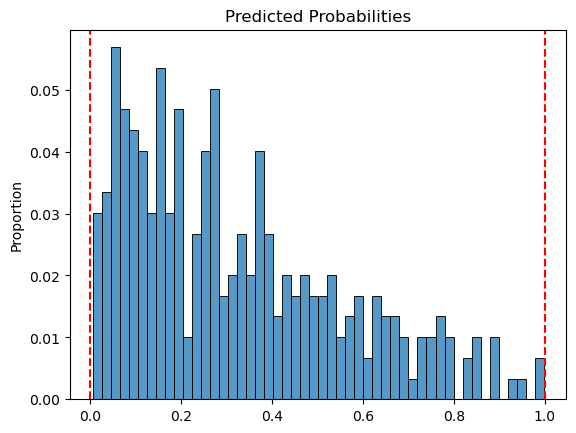

In [5]:
p_hat = model.predict(X)

sns.histplot(p_hat,stat='proportion',bins=50).set(title='Predicted Probabilities')
plt.axvline(x=0, color='red', linestyle='--')
plt.axvline(x=1, color='red', linestyle='--')

Text(0.5, 1.0, 'Predicted Probabilities')

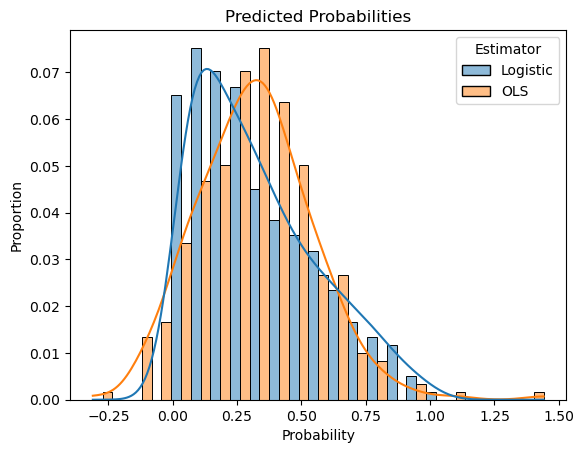

In [6]:
gdf = pd.concat(axis=0, ignore_index=True, objs=[
    pd.DataFrame.from_dict({'Probability': p_hat, 'Estimator': 'Logistic'}),
    pd.DataFrame.from_dict({'Probability': y_hat, 'Estimator': 'OLS'})])

# Probability of default:
sns.histplot(data=gdf, x='Probability', hue='Estimator', kde=True, alpha=.5,
             stat='proportion',multiple='dodge').set_title('Predicted Probabilities')

## Inference
- Bootstrap!
- For asymptotic CIs, let
$$
W = \left[ \begin{array}{cccc} \hat{p}_1(1-\hat{p}_1) & 0 & \dots & 0 \\
0 & \hat{p}_2(1-\hat{p}_2)  & \dots & 0 \\ 
\vdots & \vdots  & \ddots & \vdots \\ 
0 & 0  & \dots & \hat{p}_n(1-\hat{p}_n) 
\end{array}\right]
$$
Then 
$$
\text{SE}(\hat{\beta}_k) = \sqrt{[ X^{\top} W X]^{-1}_{kk}}
$$
We can build a 95% confidence interval for $\beta_k$ as
$$
\left( \hat{\beta}_k - 1.96 \times \sqrt{[ X^{\top} W X]^{-1}_{kk}}, \quad  \hat{\beta}_k + 1.96 \times \sqrt{[ X^{\top} W X]^{-1}_{kk}} \right) 
$$
This is exactly what StatsModels reports as the standard error and confidence interval

## Prediction
- Prediction simply requires plugging $\hat{\beta}$ into the formulas:
$$
\text{pr}[Y_i = 1 | X_i = x] = \begin{cases}
1/(1 + \exp(x_i \cdot \hat{\beta})), & \text{Logit}\\
\Phi(x_i \cdot \hat{\beta}), & \text{Probit}
\end{cases}
$$

## Exercise: Interpreting Non-Linear Effects
- For linear regression, a "small" change in variable $x_{ik}$ resulted in a $\beta_k$ change in the prediction $\hat{y}_i$ for every $i$, regardless of the values of the variables: Interpreting how changes in features changed predictions was straightforward, because for a linear model, $\partial \hat{y}/\partial x_{ik} = \beta_k$
- For logistic regression, this interpretation is incorrect, since
$$
p_i = \frac{1}{1+e^{x_i \cdot \beta}},
$$
and small changes in $x_{ik}$ do not lead to $\beta_k$ changes in $p_i$
- What's the derivative of $p_i$ with respect to $x_{ik}$?
$$
\frac{\partial p_i}{\partial x_{ik}} = \beta_k \dfrac{1}{1+e^{x_i \cdot \beta}} \dfrac{e^{ x_i \cdot \beta}}{1+e^{x_i \cdot \beta}} = \beta_k p_i (1-p_i)
$$
- So, on average across the sample, how does a change in variable $k$ impact the predictions? The **average marginal effect (AME)** is
$$
AME_k =  \dfrac{1}{n} \sum_{i=1}^n \beta_k p_i (1-p_i)
$$
- A popular alternative is to compute the probability at the average for each of the variables,
$$
\bar{p} = \frac{1}{1+e^{\bar{x} \cdot \beta}},
$$
and then compute the **marginal effect at the mean**:
$$
MEM_k = \beta_k \bar{p} (1-\bar{p})
$$
- For the METABRIC survival example, use logistic regression and OLS to predict surival. For the logistic regression model, compute the AME and MEM for your model, and compare the results to the OLS coefficients.

In [7]:
beta = model.params
X_bar = X.mean()
p_bar = 1/(1 + np.exp(-np.dot(X_bar, beta)))
MEM = beta * p_bar * (1 - p_bar)
mem_df = pd.DataFrame({
    'coef': model.params,
    'MEM': MEM
})
mem_df

,coef,MEM
const,4.964299e+00,9.814927e-01
age,5.569092e-02,1.101067e-02
anaemia,4.179298e-01,8.262899e-02
creatinine_phosphokinase,2.905410e-04,5.744294e-05
diabetes,1.514076e-01,2.993484e-02
ejection_fraction,-7.032203e-02,-1.390339e-02
high_blood_pressure,4.189377e-01,8.282827e-02
platelets,-7.093639e-07,-1.402485e-07
serum_creatinine,6.618606e-01,1.308566e-01
serum_sodium,-5.666672e-02,-1.120359e-02


In [11]:
model.get_margeff(at='mean').summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
        Logit Marginal Effects       
=====================================
Dep. Variable:            DEATH_EVENT
Method:                          dydx
At:                              mean
============================================================================================
                              dy/dx    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------
age                          0.0110      0.003      4.383      0.000       0.006       0.016
anaemia                      0.0826      0.059      1.392      0.164      -0.034       0.199
creatinine_phosphokinase  5.744e-05   2.81e-05      2.045      0.041    2.39e-06       0.000
diabetes                     0.0299      0.059      0.510      0.610      -0.085       0.145
ejection_fraction           -0.0139      0.003     -5.016      0.000      -0.019      -0.008
high_blood_pressure          0.0828      0.061      1.367      0.172      -0.036       0.202
platelets                -1.402e-07   3.19e-07     -0.440      0.660   -7.66e-07    4.85e-07
serum_creatinine             0.1309      0.035      3.718      0.000       0.062       0.200
serum_sodium                -0.0112      0.007     -1.696      0.090      -0.024       0.002
sex                         -0.0789      0.069     -1.141      0.254      -0.214       0.057
smoking                      0.0268      0.069      0.389      0.697      -0.108       0.162
============================================================================================
"""

In [12]:
model.get_margeff(at='overall').summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
        Logit Marginal Effects       
=====================================
Dep. Variable:            DEATH_EVENT
Method:                          dydx
At:                           overall
============================================================================================
                              dy/dx    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------
age                          0.0091      0.002      4.742      0.000       0.005       0.013
anaemia                      0.0679      0.048      1.403      0.161      -0.027       0.163
creatinine_phosphokinase  4.724e-05   2.27e-05      2.083      0.037    2.79e-06    9.17e-05
diabetes                     0.0246      0.048      0.510      0.610      -0.070       0.119
ejection_fraction           -0.0114      0.002     -5.434      0.000      -0.016      -0.007
high_blood_pressure          0.0681      0.049      1.384      0.166      -0.028       0.165
platelets                -1.153e-07   2.63e-07     -0.439      0.661    -6.3e-07       4e-07
serum_creatinine             0.1076      0.026      4.197      0.000       0.057       0.158
serum_sodium                -0.0092      0.005     -1.727      0.084      -0.020       0.001
sex                         -0.0649      0.057     -1.145      0.252      -0.176       0.046
smoking                      0.0220      0.057      0.389      0.697      -0.089       0.133
============================================================================================
"""